# 实验3：读取、显示及保存图像

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

掌握读图、BGR/RGB 显示、水平/垂直翻转以及保存图片。

## 实验原理

`imdecode` 解码图像（中文路径兼容封装）；`cv2.flip(image, 1)` 水平翻转，`0` 垂直翻转，`-1` 同时翻转两轴。PNG 无损，JPEG 通常有损。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab03"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 读图并检查数组

使用素材文件夹中的硬币照片。请先检查图像是否读取成功，再执行后续处理。


shape: (419, 632, 3) dtype: uint8


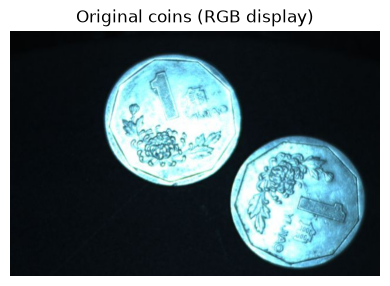

In [2]:
image = read_image(ASSETS / "pdf/coins.png")
print("shape:", image.shape, "dtype:", image.dtype)
show_images({"Original coins (RGB display)": image}, cols=1)


## 3. 翻转与保存

保存为 PNG 后重新读取，验证保存结果的像素与内存数组一致。


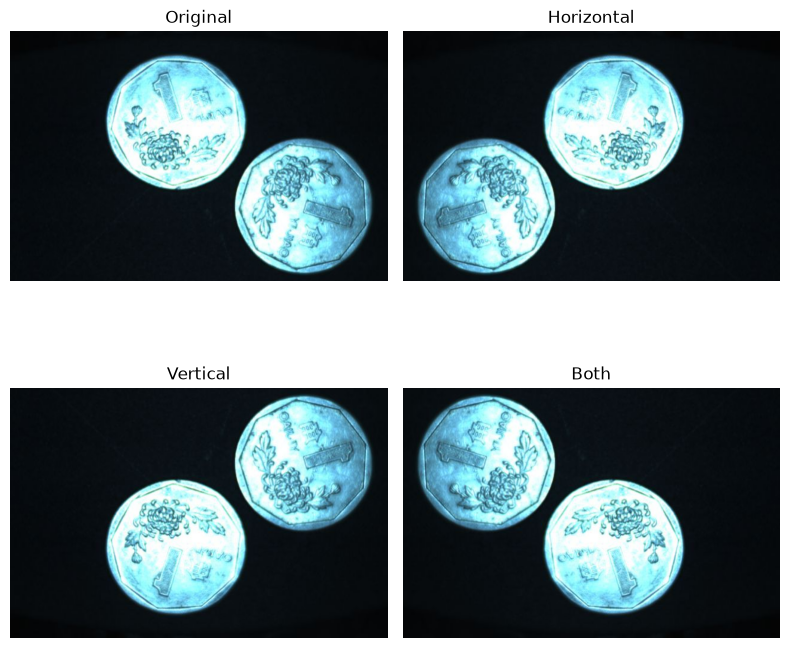

In [3]:
horizontal = cv2.flip(image, 1)
vertical = cv2.flip(image, 0)
both = cv2.flip(image, -1)
for name, result in {"horizontal": horizontal, "vertical": vertical, "both": both}.items():
    saved = save_image(OUT / f"coins_{name}.png", result)
    assert np.array_equal(read_image(saved), result)
show_images({"Original": image, "Horizontal": horizontal, "Vertical": vertical, "Both": both},
            cols=2, save_to=OUT / "flip_comparison.png")


## 4. 用熊猫照片重复实验

更换输入素材，不必改动算法。输出单独保存。


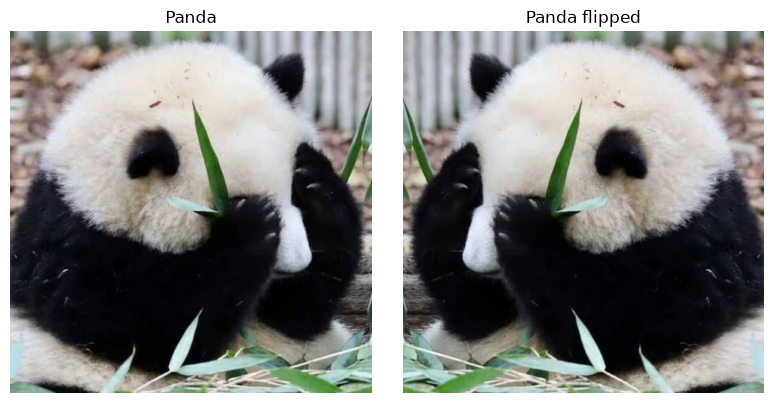

In [4]:
panda = read_image(ASSETS / "user/panda.jpg")
panda_flipped = cv2.flip(panda, 1)
save_image(OUT / "panda_horizontal.png", panda_flipped)
show_images({"Panda": panda, "Panda flipped": panda_flipped}, cols=2)


## 作业：导出对比图

使用原图和水平翻转结果生成一张对比图。运行后将结果复制到自己的提交目录。

提交要求见 [一次实验作业](../assignments/README.md)。

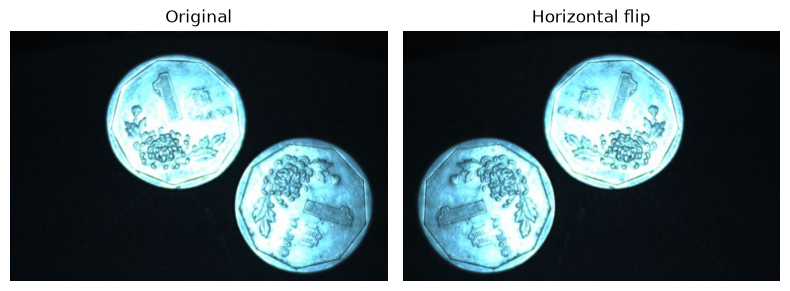

作业图片已保存到： /Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab03/01_flip.png


In [5]:
show_images({"Original": image, "Horizontal flip": horizontal}, cols=2,
            save_to=OUT / "01_flip.png")
print("作业图片已保存到：", OUT / "01_flip.png")

## 记录与思考

1. 将 `flip` 参数改为 0 和 -1，解释变化。
2. 为什么彩色图不能直接交给 Matplotlib 显示？
3. 尝试把结果保存成 JPEG，与 PNG 文件大小比较；不要假设 JPEG 重新读取后逐像素相同。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab03/`；运行本 Notebook 不会改写原始素材。
